# Camino del terreno — Fases 4 y 5: quebradas finales y tabla de terreno

- **Fase 4:** delimito las quebradas ubicadas a mano en `pendientes_ubicar.csv`, reviso problemas y alias, y armo `alias_catalogo.csv`.
- **Fase 5:** tabla de terreno `quebradas.csv` (área, pendiente, cotas, Melton, largo del cauce) y susceptibilidad INGEMMET.

La primera parte (rasters, red D8, cauce principal) es la misma preparación de la fase 3.

In [1]:
from pathlib import Path
import unicodedata, difflib, tempfile
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
import shapely
from rasterio import features
from rasterio.warp import transform as warp_transform
from scipy import ndimage as ndi
from scipy.spatial import cKDTree
from shapely.geometry import Point, box, shape
from shapely.ops import linemerge, unary_union
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import whitebox

# --- Parámetros ---
UMBRAL_CAUCE = 500           # celdas; el mismo de la fase 1 (elegido en el paso 12; antes 1000)
UMBRALES = [500, 1000, 2500, 5000]
BUFFER_M = 90
SNAP_UMBRAL = 100            # celdas: cauces a los que se ajusta un punto de referencia
SNAP_MAX_M = 150
PASO_CONSULTA_M = 150        # la consulta empieza 150 m aguas arriba de la salida, sobre la línea de ANA...
MAX_CONSULTA_M = 1000        # ...y sube por la línea (cada 30 m) hasta 1 km buscando la primera cuenca candidata
CELDA_M2 = 900

TERRENO = Path.cwd().resolve()
RAIZ = TERRENO.parent
FUENTES = TERRENO / "fuentes"
DEM, FDIR, FACC = RAIZ / "fabdem_chosica_hydro.tif", RAIZ / "flow_direction_d8.tif", RAIZ / "flow_accumulation_d8.tif"

wbt = whitebox.WhiteboxTools()
wbt.set_verbose_mode(False)

0

In [2]:
with rasterio.open(DEM) as src:
    dem = src.read(1); perfil = src.profile; T = src.transform; CRS = src.crs
with rasterio.open(FDIR) as src:
    fdir = src.read(1)
with rasterio.open(FACC) as src:
    acc = src.read(1); valido = acc != src.nodata
with rasterio.open(TERRENO / "cauce_principal.tif") as src:
    rio = src.read(1)                     # 1 = Rímac, 2 = Santa Eulalia
with rasterio.open(TERRENO / "cuencas_candidatas.tif") as src:
    ws = src.read(1); ws = np.where((ws == src.nodata) | ~valido, 0, ws).astype(np.int32)
R, C = acc.shape
principal = rio > 0
borde = valido & ~ndi.binary_erosion(valido, structure=np.ones((3, 3)), border_value=0)
pp = pd.read_csv(TERRENO / "pour_points_candidatos.csv")
cand = gpd.read_file(TERRENO / "cuencas_candidatas.geojson").to_crs(CRS).set_index("cuenca_id")

# Red D8 (convención Whitebox)
D8 = {1: (-1, 1), 2: (0, 1), 4: (1, 1), 8: (1, 0), 16: (1, -1), 32: (0, -1), 64: (-1, -1), 128: (-1, 0)}
idx = np.arange(R * C).reshape(R, C)
abajo = np.full(R * C, -1)
for d, (dr, dc) in D8.items():
    rr, cc = np.where((fdir == d) & valido)
    r2, c2 = rr + dr, cc + dc
    ok = (r2 >= 0) & (r2 < R) & (c2 >= 0) & (c2 < C)
    ok[ok] &= valido[r2[ok], c2[ok]]
    abajo[idx[rr[ok], cc[ok]]] = idx[r2[ok], c2[ok]]
salida_final = np.where(abajo < 0, np.arange(R * C), abajo)
for _ in range(30):
    salida_final = salida_final[salida_final]
salida_final = salida_final.reshape(R, C)
paso_m = np.where(np.isin(fdir, [1, 4, 16, 64]), 30 * np.sqrt(2), 30.0)   # largo del paso D8 de cada celda

def trazar(r, c, mascara):
    camino = [(r, c)]
    while abajo[idx[r, c]] >= 0:
        r, c = divmod(int(abajo[idx[r, c]]), C)
        if not mascara[r, c]: break
        camino.append((r, c))
    return camino

def entrada(mascara):
    # Celda del río sin otra celda del mismo río aguas arriba
    celdas = idx[mascara]
    return divmod(int(np.setdiff1d(celdas, abajo[celdas])[0]), C)

traza = {"Rímac": trazar(*entrada(rio == 1), rio == 1), "Santa Eulalia": trazar(*entrada(rio == 2), rio == 2)}
salida_rimac = traza["Rímac"][-1]
zona_rimac = valido & (salida_final == salida_final[salida_rimac])     # todo lo que drena a la salida del Rímac

xy_rio = {k: np.array(rasterio.transform.xy(T, *zip(*v))).T for k, v in traza.items()}
arbol_rio = {k: cKDTree(v) for k, v in xy_rio.items()}

def ubicar(x, y):
    # Río más cercano, km desde la salida (Rímac) o desde la confluencia (Santa Eulalia), margen y distancia.
    mejor = min(((k, *arbol_rio[k].query([x, y])) for k in xy_rio), key=lambda t: t[1])
    k, dist, i = mejor; v = xy_rio[k]
    i0, i1 = max(i - 5, 0), min(i + 5, len(v) - 1)
    dx, dy = v[i1] - v[i0]                     # sentido aguas abajo
    px, py = x - v[i, 0], y - v[i, 1]
    margen = "izquierda" if dx * py - dy * px > 0 else "derecha"
    return k, round((len(v) - 1 - i) * 0.03, 2), margen, round(dist)

xs, ys = rasterio.transform.xy(T, *np.where(principal))
arbol_principal = cKDTree(np.c_[xs, ys])
X0, Y0, X1, Y1 = rasterio.transform.array_bounds(R, C, T)
zona_valida = unary_union([shape(g) for g, v in features.shapes(valido.astype(np.uint8), mask=valido, transform=T)])

def hillshade(z, az=315, alt=45):
    z = np.where(valido, z, np.nan)
    gy, gx = np.gradient(z, 30)
    pend = np.arctan(np.hypot(gx, gy)); asp = np.arctan2(-gx, gy)
    az, alt = np.radians(360 - az + 90), np.radians(alt)
    return np.ma.masked_invalid(np.sin(alt) * np.cos(pend) + np.cos(alt) * np.sin(pend) * np.cos(az - asp))
hs = hillshade(dem)
print("Rímac:", len(traza["Rímac"]), "celdas | Santa Eulalia:", len(traza["Santa Eulalia"]), "| cuencas candidatas:", len(cand))

Rímac: 1138 celdas | Santa Eulalia: 482 | cuencas candidatas: 89


In [3]:
def cauce_arriba(r, c):
    # Largo (km) del cauce principal: desde (r, c) hacia arriba por la mayor acumulación, mientras acc >= UMBRAL_CAUCE.
    largo = 0.0
    while True:
        mejor = None
        for dr in (-1, 0, 1):
            for dc in (-1, 0, 1):
                r2, c2 = r + dr, c + dc
                if (dr or dc) and 0 <= r2 < R and 0 <= c2 < C and abajo[idx[r2, c2]] == idx[r, c] and acc[r2, c2] >= UMBRAL_CAUCE:
                    if mejor is None or acc[r2, c2] > acc[mejor]: mejor = (r2, c2)
        if mejor is None: return largo / 1000
        largo += paso_m[mejor]; r, c = mejor

## Fase 4 — Delimitar las quebradas ubicadas a mano (`pendientes_ubicar.csv`)
- **Regla:** la misma de la fase 3. Ajuste (*snap*) al cauce más cercano con acumulación ≥ 100 celdas, como máximo a 150 m y sin contar el cauce principal; luego `watershed` desde ese punto. Los ids son P01, P02…, en el orden del archivo.
  - Excepción aceptada: Huampaní, cuyo cauce está a 206 m; se ajusta con un máximo de 250 m y queda con `confianza_cuenca = "baja"`.
- **Corrección:** si una longitud viene con signo positivo, se corrige a negativa (+76° cae fuera del Perú) y queda anotado.

In [4]:
from collections import Counter
import re
def normalizar(t):
    t = unicodedata.normalize("NFKD", str(t)).encode("ascii", "ignore").decode().lower().strip()
    for pre in ("quebrada ", "rio "):
        if t.startswith(pre): t = t[len(pre):]
    return t
ana = {"ANA Estudios": gpd.read_file(FUENTES / "ana_rios_quebradas_estudios.geojson").to_crs(CRS),
       "ANA Carta IGN": gpd.read_file(FUENTES / "ana_rios_quebradas_carta_ign.geojson").to_crs(CRS)}
ref = pd.read_csv(TERRENO / "quebradas_referencia.csv")
cruce3 = pd.read_csv(TERRENO / "cruce_referencia.csv", dtype={"cuenca_id": str})
g_ref = gpd.read_file(TERRENO / "cuencas_referencia.geojson").to_crs(CRS).set_index("cuenca_id")
pend = pd.read_csv(TERRENO / "pendientes_ubicar.csv")
cat = pd.read_csv(RAIZ / "catalogo_huaicos_chosica" / "catalogo_huaicos_chosica.csv")
cat_p = cat[cat.en_piloto]

correcciones = {}
for i in pend.index[pend.salida_lon > 0]:
    correcciones[pend.loc[i, "nombre"]] = f"salida_lon {pend.loc[i, 'salida_lon']} corregida a {-pend.loc[i, 'salida_lon']} (signo)"
    pend.loc[i, "salida_lon"] = -pend.loc[i, "salida_lon"]
print("Correcciones:", correcciones)

snap_mask = (acc >= SNAP_UMBRAL) & valido & ~principal
sr, sc = np.where(snap_mask)
arbol_snap = cKDTree(np.array(rasterio.transform.xy(T, sr, sc)).T)
tmp = Path(tempfile.mkdtemp())
perfil_i32 = perfil.copy(); perfil_i32.update(dtype="int32", nodata=0, compress="lzw")

def watershed_desde(r, c):
    pour = np.zeros((R, C), np.int32); pour[r, c] = 1
    with rasterio.open(tmp / "pp.tif", "w", **perfil_i32) as dst: dst.write(pour, 1)
    assert wbt.watershed(str(FDIR), str(tmp / "pp.tif"), str(tmp / "ws.tif")) == 0
    with rasterio.open(tmp / "ws.tif") as src: m = src.read(1) == 1
    return m & valido

def poligono(m):
    return shapely.make_valid(unary_union([shape(g) for g, v in features.shapes(m.astype(np.uint8), mask=m, transform=T, connectivity=4)]))

def mascara_poligono(geom):
    return features.rasterize([(geom, 1)], out_shape=(R, C), transform=T, fill=0, dtype="uint8").astype(bool) & valido

# Máscaras de las cuencas con nombre de la fase 3 (candidatas y delimitadas desde ANA)
mascaras = {}            # nombre -> (cuenca_id, máscara)
for _, f in cruce3[cruce3.origen.isin(["candidata", "referencia"])].iterrows():
    cid = f.cuenca_id
    m = (ws == int(cid)) if cid.isdigit() else mascara_poligono(g_ref.loc[cid, "geometry"])
    mascaras[f.nombre] = (cid, m)
print("Cuencas con nombre de la fase 3:", len(mascaras))

Correcciones: {'El Vallecito': 'salida_lon 76.78432 corregida a -76.78432 (signo)'}


Cuencas con nombre de la fase 3: 69


In [5]:
# Excepción aceptada (decisión fase 4): Huampaní con snap de hasta 250 m (su cauce está a 206 m) y confianza baja
SNAP_EXCEPCIONES = {"Huampaní": 250}
filas, pol_p = [], {}
pend_xy = pend.dropna(subset=["salida_lat", "salida_lon"]).copy()
xs_p, ys_p = warp_transform("EPSG:4326", CRS, pend_xy.salida_lon.tolist(), pend_xy.salida_lat.tolist())
for k, (i, f) in enumerate(pend_xy.iterrows()):
    x, y = xs_p[k], ys_p[k]
    d, j = arbol_snap.query([x, y])
    fila = {"quebrada": f.nombre, "n_eventos": f.n_eventos, "distancia_snap_m": round(d),
            "dist_cauce_principal_m": round(float(arbol_principal.query([x, y])[0])), "nota": correcciones.get(f.nombre, "")}
    max_m = SNAP_EXCEPCIONES.get(f.nombre, SNAP_MAX_M)
    if d > max_m:
        fila.update(cuenca="", nota=" | ".join(filter(None, [fila["nota"], f"sin cauce a ≤ {max_m} m"])))
        filas.append(fila); continue
    if d > SNAP_MAX_M:
        fila["nota"] = " | ".join(filter(None, [fila["nota"], f"snap {d:.0f} m > {SNAP_MAX_M} m aceptado (excepción); confianza baja"]))
    r0, c0 = int(sr[j]), int(sc[j])
    m = watershed_desde(r0, c0)
    assert m.sum() == acc[r0, c0]
    cid = f"P{k + 1:02d}"
    cc_ = int(ws[r0, c0]); frac = m.sum() / (ws == cc_).sum() if cc_ else np.nan
    mascaras[f.nombre] = (cid, m); pol_p[cid] = (f.nombre, poligono(m), r0, c0)
    fila.update(cuenca=cid, area_km2=round(m.sum() * CELDA_M2 / 1e6, 3), cota_max_m=round(float(dem[m].max())),
                igual_a_candidata=cc_ if cc_ and frac >= 0.95 else "", candidata_que_contiene=cc_ or "",
                pct_de_la_candidata=round(100 * frac) if cc_ else np.nan,
                toca_borde=bool((m & borde).any()))
    filas.append(fila)
tabla_p = pd.DataFrame(filas)

# Igualdad con otras cuencas con nombre: IoU >= 0.95
def comparar(a, b):
    ma, mb = mascaras[a][1], mascaras[b][1]
    inter = (ma & mb).sum()
    return {"iou": inter / (ma | mb).sum(), "frac_a_en_b": inter / ma.sum(), "frac_b_en_a": inter / mb.sum()}

iguales = []
for q in tabla_p.loc[tabla_p.cuenca != "", "quebrada"]:
    otras = [n for n in mascaras if n != q and comparar(q, n)["iou"] >= 0.95]
    iguales.append(", ".join(otras))
tabla_p.loc[tabla_p.cuenca != "", "igual_a_otra_con_nombre"] = iguales

def problemas(f):
    p = []
    if f.cuenca == "": return "sin cuenca"
    if f.area_km2 < 0.3: p.append("área < 0.3 km²")
    if f.area_km2 > 30: p.append("área > 30 km²")
    if f.toca_borde: p.append("toca el borde")
    if f.distancia_snap_m > SNAP_MAX_M: p.append(f"snap > {SNAP_MAX_M} m (aceptado, confianza baja)")
    if isinstance(f.igual_a_otra_con_nombre, str) and f.igual_a_otra_con_nombre: p.append("igual a " + f.igual_a_otra_con_nombre)
    return ", ".join(p)
tabla_p["problemas"] = tabla_p.apply(problemas, axis=1)
cols_p = ["quebrada", "cuenca", "area_km2", "cota_max_m", "igual_a_candidata", "distancia_snap_m", "toca_borde",
          "dist_cauce_principal_m", "candidata_que_contiene", "pct_de_la_candidata", "igual_a_otra_con_nombre", "problemas", "nota"]
tabla_p[cols_p].to_csv(TERRENO / "cuencas_ubicadas.csv", index=False, encoding="utf-8-sig")
g_p = gpd.GeoDataFrame({"cuenca_id": list(pol_p), "nombre": [v[0] for v in pol_p.values()]}, geometry=[v[1] for v in pol_p.values()], crs=CRS)
g_p = g_p.merge(tabla_p[["cuenca", "area_km2", "cota_max_m", "toca_borde"]].rename(columns={"cuenca": "cuenca_id"}), on="cuenca_id")
g_p.to_crs("EPSG:4326").to_file(TERRENO / "cuencas_ubicadas.geojson", driver="GeoJSON")
g_p.to_crs("EPSG:4326").assign(Name=lambda d: d.cuenca_id + " " + d.nombre, toca_borde=lambda d: d.toca_borde.astype(str)).to_file(TERRENO / "cuencas_ubicadas.kml", driver="KML")
display(tabla_p[cols_p])

,quebrada,cuenca,area_km2,cota_max_m,igual_a_candidata,distancia_snap_m,toca_borde,dist_cauce_principal_m,candidata_que_contiene,pct_de_la_candidata,igual_a_otra_con_nombre,problemas,nota
0,Chacrasana,P01,4.561,1804,,134,False,448,25,91.0,,,
1,Yanacoto,P02,3.280,1856,,60,False,1097,30,78.0,,,
2,Libertad,P03,0.408,1527,,2,False,632,38,67.0,,,
3,Mariscal Castilla,P04,0.770,1723,,51,False,664,39,58.0,,,
4,Rosario,P05,0.135,1576,,23,False,462,,NaN,,área < 0.3 km²,
5,Santo Domingo (Chosica),P06,3.554,1922,,21,False,852,36,94.0,,,
6,El Vallecito,P07,0.942,1502,,112,False,2405,13,6.0,,,salida_lon 76.78432 corregida a -76.78432 (signo)
7,Inca Kola,P08,0.444,1679,,16,False,409,41,84.0,,,
8,Alto Perú,P09,0.209,1070,,87,False,735,7,35.0,,área < 0.3 km²,
9,Buenos Aires (Chosica),P10,0.149,1348,,14,False,574,39,11.0,,área < 0.3 km²,


### Comparaciones específicas
- **Coincidencia:** `iou` = celdas compartidas / celdas de la unión (1 = idénticas); `frac_a_en_b` = qué parte de A cae dentro de B.
- **Ramas:** recorro el cauce principal desde la salida hacia arriba (siempre por la mayor acumulación). En cada confluencia anoto los afluentes de ≥ 0.2 km², con su área y el rumbo desde la confluencia al centro del afluente.

In [6]:
orden_up = np.argsort(abajo, kind="stable"); abajo_ord = abajo[orden_up]
acc_r, paso_r = acc.ravel(), paso_m.ravel()
def hijos(i):
    lo, hi = np.searchsorted(abajo_ord, [i, i + 1]); return orden_up[lo:hi]
def aguas_arriba(i):
    pila, out = [i], []
    while pila:
        v = pila.pop(); out.append(v); pila.extend(hijos(v).tolist())
    return np.array(out)
RUMBOS = ["N", "NE", "E", "SE", "S", "SO", "O", "NO"]
def rumbo(i_desde, celdas):
    r0, c0 = divmod(int(i_desde), C); rr, cc = np.divmod(celdas, C)
    dx, dy = (cc.mean() - c0) * 30, -(rr.mean() - r0) * 30
    az = (np.degrees(np.arctan2(dx, dy)) + 360) % 360
    return round(az), RUMBOS[int(((az + 22.5) % 360) // 45)]
def ramas(nombre, min_km2=0.2):
    cid, m = mascaras[nombre]
    r0, c0 = (pol_p[cid][2], pol_p[cid][3]) if cid in pol_p else np.unravel_index(np.argmax(np.where(m, acc, 0)), acc.shape)
    i, dist, out = idx[r0, c0], 0.0, []
    while True:
        h = hijos(i)
        if len(h) == 0: break
        h = h[np.argsort(-acc_r[h])]
        for t in h[1:]:
            a = acc_r[t] * CELDA_M2 / 1e6
            if a >= min_km2:
                az, rb = rumbo(i, aguas_arriba(t))
                azm, rbm = rumbo(i, aguas_arriba(h[0]))
                out.append({"km_desde_salida": round(dist / 1000, 2), "afluente_km2": round(a, 2), "afluente_rumbo": f"{rb} ({az}°)",
                            "sigue_principal_km2": round(acc_r[h[0]] * CELDA_M2 / 1e6, 2), "principal_rumbo": f"{rbm} ({azm}°)"})
        dist += paso_r[h[0]]; i = h[0]
        if acc_r[i] * CELDA_M2 / 1e6 < min_km2: break
    return pd.DataFrame(out)

def mostrar_comparacion(a, b):
    c = comparar(a, b); ca, cb = mascaras[a], mascaras[b]
    return {"A": f"{a} ({ca[0]})", "B": f"{b} ({cb[0]})", "area_A_km2": round(ca[1].sum() * CELDA_M2 / 1e6, 3),
            "area_B_km2": round(cb[1].sum() * CELDA_M2 / 1e6, 3), "iou": round(c["iou"], 3),
            "frac_A_en_B": round(c["frac_a_en_b"], 3), "frac_B_en_A": round(c["frac_b_en_a"], 3)}

pares = [("Inca Kola", "Carossio"), ("Libertad", "Pedregal"), ("Libertad", "Carossio"), ("Libertad", "Corrales"),
         ("Buenos Aires (Chosica)", "Mariscal Castilla"), ("Yanacoto", "Chacrasana"), ("Yanacoto", "Quebrada Santa María")]
comp = pd.DataFrame([mostrar_comparacion(a, b) for a, b in pares if a in mascaras and b in mascaras])
display(comp)
m_ik = mascaras["Inca Kola"][1]
print(f"Inca Kola: área {m_ik.sum() * CELDA_M2 / 1e6:.3f} km², cota máx {dem[m_ik].max():.0f} m | Cuadro 04 Carossio: 0.4 km², 1675 m")
print("\nRamas de Yanacoto:"); display(ramas("Yanacoto"))
print("Ramas de Huampaní:"); display(ramas("Huampaní", min_km2=0.05))

,A,B,area_A_km2,area_B_km2,iou,frac_A_en_B,frac_B_en_A
0,Inca Kola (P08),Carossio (41),0.444,0.528,0.840,1.0,0.840
1,Libertad (P03),Pedregal (37),0.408,9.982,0.000,0.0,0.000
2,Libertad (P03),Carossio (41),0.408,0.528,0.000,0.0,0.000
3,Libertad (P03),Corrales (42),0.408,1.259,0.000,0.0,0.000
4,Buenos Aires (Chosica) (P10),Mariscal Castilla (P04),0.149,0.770,0.000,0.0,0.000
5,Yanacoto (P02),Chacrasana (P01),3.280,4.561,0.000,0.0,0.000
6,Yanacoto (P02),Quebrada Santa María (30),3.280,4.200,0.781,1.0,0.781


Inca Kola: área 0.444 km², cota máx 1679 m | Cuadro 04 Carossio: 0.4 km², 1675 m

Ramas de Yanacoto:


,km_desde_salida,afluente_km2,afluente_rumbo,sigue_principal_km2,principal_rumbo
0,0.21,0.36,O (286°),2.83,N (338°)
1,0.82,0.31,O (286°),2.29,N (345°)
2,0.92,0.92,N (15°),1.33,NO (323°)
3,0.97,0.22,NO (300°),1.11,NO (327°)
4,1.65,0.36,N (343°),0.48,NO (306°)


Ramas de Huampaní:


,km_desde_salida,afluente_km2,afluente_rumbo,sigue_principal_km2,principal_rumbo
0,0.04,0.09,NO (298°),3.39,NO (332°)
1,0.47,1.25,N (4°),2.07,NO (317°)
2,0.70,0.08,N (346°),1.97,NO (315°)
3,0.93,0.51,N (346°),1.39,NO (309°)
4,0.97,0.17,O (270°),1.21,NO (310°)
5,1.56,0.09,N (351°),0.95,NO (307°)
6,1.95,0.07,SO (245°),0.65,NO (329°)
7,2.07,0.24,O (276°),0.40,N (359°)
8,2.32,0.07,NO (332°),0.23,N (17°)
9,2.57,0.06,N (345°),0.08,NE (27°)


In [7]:
# Santo Domingo (Chosica) vs resolución SIGRID 19950 (faja marginal, ANA): tramo de 1.48 km, sin área de cuenca
SD = {"inicio tramo": (314760, 8678985), "fin tramo": (315919, 8678404), "verificación (cauce 6.5 m)": (314701, 8679015)}
cid_sd, m_sd = mascaras["Santo Domingo (Chosica)"]
pol_sd = poligono(m_sd)
for k_, (x, y) in SD.items():
    rr_, cc_ = rasterio.transform.rowcol(T, x, y)
    otras = [f"{n} ({mascaras[n][0]})" for n in mascaras if mascaras[n][1][rr_, cc_] and n != "Santo Domingo (Chosica)"]
    rio_, km_, margen_, dist_ = ubicar(x, y)
    print(f"{k_}: dentro de {cid_sd}: {pol_sd.contains(Point(x, y))} | a {pol_sd.boundary.distance(Point(x, y)):.0f} m del borde de {cid_sd} "
          f"| candidata en la celda: {int(ws[rr_, cc_]) or 'ninguna'} | otras con nombre: {otras or 'ninguna'} | a {dist_} m del {rio_} ({margen_}, km {km_})")
r0, c0 = pol_p[cid_sd][2], pol_p[cid_sd][3]
print(f"Largo de nuestro cauce (≥ {UMBRAL_CAUCE} celdas): {cauce_arriba(r0, c0):.2f} km | tramo de la faja marginal: 1.48 km (no es el largo total)")
print(f"Área de nuestra cuenca: {m_sd.sum() * CELDA_M2 / 1e6:.2f} km² | SIGRID 19950 no reporta área de cuenca")

inicio tramo: dentro de P06: False | a 937 m del borde de P06 | candidata en la celda: ninguna | otras con nombre: ninguna | a 118 m del Rímac (izquierda, km 17.04)
fin tramo: dentro de P06: True | a 309 m del borde de P06 | candidata en la celda: 36 | otras con nombre: ninguna | a 1241 m del Rímac (izquierda, km 17.4)
verificación (cauce 6.5 m): dentro de P06: False | a 998 m del borde de P06 | candidata en la celda: ninguna | otras con nombre: ninguna | a 54 m del Rímac (izquierda, km 17.01)
Largo de nuestro cauce (≥ 500 celdas): 2.47 km | tramo de la faja marginal: 1.48 km (no es el largo total)
Área de nuestra cuenca: 3.55 km² | SIGRID 19950 no reporta área de cuenca


### Anidamiento: cuencas ubicadas contenidas en otra cuenca con nombre
El criterio de "igual" (IoU ≥ 0.95) no detecta una cuenca que cae entera dentro de otra. Agrego el problema **"contenida en X"** cuando ≥ 95 % de la cuenca ubicada cae dentro de otra cuenca con nombre.

In [8]:
anid = []
for _, f in tabla_p[tabla_p.cuenca != ""].iterrows():
    for n, (cid, m) in mascaras.items():
        if n == f.quebrada: continue
        c = comparar(f.quebrada, n)
        if c["frac_a_en_b"] >= 0.95 and c["iou"] < 0.95:
            anid.append({"quebrada": f.quebrada, "contenida_en": f"{n} ({cid})", "iou": round(c["iou"], 2), "pct_de_la_otra": round(100 * c["frac_b_en_a"])})
anid = pd.DataFrame(anid); display(anid)
for _, a in anid.iterrows():
    i = tabla_p.index[tabla_p.quebrada == a.quebrada][0]
    tabla_p.loc[i, "problemas"] = ", ".join(filter(None, [tabla_p.loc[i, "problemas"], f"contenida en {a.contenida_en} ({a.pct_de_la_otra} % de ella)"]))
tabla_p[cols_p].to_csv(TERRENO / "cuencas_ubicadas.csv", index=False, encoding="utf-8-sig")
display(tabla_p[["quebrada", "cuenca", "area_km2", "problemas"]])

,quebrada,contenida_en,iou,pct_de_la_otra
0,Yanacoto,Quebrada Santa María (30),0.78,78
1,El Vallecito,Quebrada Vizcachera (13),0.06,6
2,Inca Kola,Carossio (41),0.84,84


,quebrada,cuenca,area_km2,problemas
0,Chacrasana,P01,4.561,
1,Yanacoto,P02,3.280,contenida en Quebrada Santa María (30) (78 % d...
2,Libertad,P03,0.408,
3,Mariscal Castilla,P04,0.770,
4,Rosario,P05,0.135,área < 0.3 km²
5,Santo Domingo (Chosica),P06,3.554,
6,El Vallecito,P07,0.942,contenida en Quebrada Vizcachera (13) (6 % de ...
7,Inca Kola,P08,0.444,contenida en Carossio (41) (84 % de ella)
8,Alto Perú,P09,0.209,área < 0.3 km²
9,Buenos Aires (Chosica),P10,0.149,área < 0.3 km²


### Tarazona (no se delimita)
¿El punto -11.944207, -76.709379 cae dentro de la cuenca de Quirio o de Santa María, o a menos de 300 m de su salida?

In [9]:
xt, yt = warp_transform("EPSG:4326", CRS, [-76.709379], [-11.944207]); xt, yt = xt[0], yt[0]
rt, ct = rasterio.transform.rowcol(T, xt, yt)
dentro = {n: True for n in mascaras if mascaras[n][1][rt, ct]}
salidas = {}
for n in ["Quebrada Quirio", "Quebrada Santa María"]:
    q = pp[pp.cuenca_id == int(mascaras[n][0])].iloc[0]
    xq, yq = rasterio.transform.xy(T, q.fila, q.col); salidas[n] = round(float(np.hypot(xq - xt, yq - yt)))
rio_t, km_t, margen_t, dist_t = ubicar(xt, yt)
print(f"Tarazona: cuencas con nombre que contienen el punto: {list(dentro) or 'ninguna'} | candidata en la celda: {int(ws[rt, ct]) or 'ninguna'}")
print(f"Distancia a la salida: {salidas} | punto a {dist_t} m del {rio_t}, margen {margen_t}, km {km_t}")
tarazona_alias = next((n for n in ["Quebrada Quirio", "Quebrada Santa María"] if n in dentro or salidas[n] < 300), None)
print("Tarazona → alias de:", tarazona_alias)

Tarazona: cuencas con nombre que contienen el punto: ['Quebrada Quirio'] | candidata en la celda: 34
Distancia a la salida: {'Quebrada Quirio': 117, 'Quebrada Santa María': 2376} | punto a 140 m del Rímac, margen derecha, km 16.29
Tarazona → alias de: Quebrada Quirio


### Quebradas finales del piloto (decisiones de la fase 4)
- **Yanacoto** se fusiona con Santa María: una sola quebrada, "Santa María (Yanacoto)", con la cuenca 30.
- **Chacrasana** usa la candidata 25 y **Santo Domingo** la 36: así la cuenca incluye el cono hasta la confluencia. Sus cuencas de ápice (P01, P06) se guardan en `cuencas_apice_alternativas.geojson`.
- **Huampaní:** se acepta el *snap* de 206 m, con `confianza_cuenca = "baja"`.
- **Alias:** Inca Kola → Carossio y Tarazona → Quirio.
- `salida_tipo`: "confluencia" si la cuenca llega hasta el Rímac o el Santa Eulalia; "apice" si parte del punto ubicado a mano (el cono queda fuera). `cuenca_pequena` = área < 0.3 km².
- `quebrada_id` = nombre corto en minúsculas, sin tildes.

In [10]:
def slug(t):
    t = normalizar(t).replace("(chosica)", "").replace("(yanacoto)", "").strip()
    return re.sub(r"[^a-z0-9]+", "_", t).strip("_")

USAR_CANDIDATA = {"Chacrasana": 25, "Santo Domingo (Chosica)": 36}     # en vez de la cuenca de ápice P
FUSIONADAS = {"Yanacoto": "Quebrada Santa María"}                      # se fusiona con esa quebrada
NOMBRE_FINAL = {"Quebrada Santa María": "Santa María (Yanacoto)"}
ALIAS_CUENCA = {"Inca Kola": "Carossio"}                               # su cuenca P cae dentro de la otra

finales = []
c3 = cruce3[(cruce3.en_piloto == True) & cruce3.origen.isin(["candidata", "referencia"])]
for _, f in c3.iterrows():
    finales.append({"quebrada_id": slug(f.nombre), "nombre": NOMBRE_FINAL.get(f.nombre, f.nombre.replace("Quebrada ", "")), "nombre_ref": f.nombre,
                    "cuenca_id": f.cuenca_id, "origen": "candidata" if f.cuenca_id.isdigit() else "referencia", "fuente": f.fuente,
                    "salida_tipo": "confluencia", "confianza_cuenca": "alta"})
for _, f in tabla_p[tabla_p.cuenca != ""].iterrows():
    if f.quebrada in ALIAS_CUENCA or f.quebrada in FUSIONADAS: continue
    cand_id = USAR_CANDIDATA.get(f.quebrada)
    finales.append({"quebrada_id": slug(f.quebrada), "nombre": f.quebrada.replace(" (Chosica)", ""), "nombre_ref": f.quebrada,
                    "cuenca_id": str(cand_id) if cand_id else f.cuenca, "origen": "ubicada",
                    "fuente": "manual (pendientes_ubicar.csv)" + (f"; cuenca = candidata {cand_id} (incluye el cono)" if cand_id else ""),
                    "salida_tipo": "confluencia" if cand_id else "apice",
                    "confianza_cuenca": "baja" if f.distancia_snap_m > SNAP_MAX_M else "alta"})
fin = pd.DataFrame(finales)
assert fin.quebrada_id.is_unique

def mascara_final(f):
    cid = f.cuenca_id
    if cid.isdigit(): return ws == int(cid)
    if cid.startswith("R"): return mascara_poligono(g_ref.loc[cid, "geometry"])
    return mascaras[f.nombre_ref][1]
def salida_final_rc(f):
    cid = f.cuenca_id
    if cid.isdigit():
        q = pp[pp.cuenca_id == int(cid)].iloc[0]; return int(q.fila), int(q.col)
    if cid in pol_p: return pol_p[cid][2], pol_p[cid][3]
    m = mascara_final(f); return np.unravel_index(np.argmax(np.where(m, acc, 0)), acc.shape)
masc_fin = {f.quebrada_id: mascara_final(f) for _, f in fin.iterrows()}
rc_fin = {f.quebrada_id: salida_final_rc(f) for _, f in fin.iterrows()}
fin["area_km2"] = fin.quebrada_id.map(lambda q: round(masc_fin[q].sum() * CELDA_M2 / 1e6, 3))
fin["cuenca_pequena"] = fin.area_km2 < 0.3
# Las cuencas finales no se solapan
sol = [(a, b) for i, a in enumerate(fin.quebrada_id) for b in fin.quebrada_id[i + 1:] if (masc_fin[a] & masc_fin[b]).any()]
print("Pares de cuencas finales que se solapan:", sol or "ninguno")

# Cuencas de ápice alternativas (P01, P06)
alt = [(slug(n), tabla_p.loc[tabla_p.quebrada == n, "cuenca"].iloc[0]) for n in USAR_CANDIDATA]
g_alt = gpd.GeoDataFrame({"quebrada_id": [q for q, _ in alt], "cuenca_id": [c for _, c in alt],
                          "area_km2": [round(mascaras[n][1].sum() * CELDA_M2 / 1e6, 3) for n in USAR_CANDIDATA],
                          "candidata_usada": [USAR_CANDIDATA[n] for n in USAR_CANDIDATA]},
                         geometry=[pol_p[c][1] for _, c in alt], crs=CRS)
g_alt.to_crs("EPSG:4326").to_file(TERRENO / "cuencas_apice_alternativas.geojson", driver="GeoJSON")
display(g_alt.drop(columns="geometry"))

Pares de cuencas finales que se solapan: ninguno


,quebrada_id,cuenca_id,area_km2,candidata_usada
0,chacrasana,P01,4.561,25
1,santo_domingo,P06,3.554,36


### `alias_catalogo.csv`: nombre del catálogo → `quebrada_id`

In [11]:
ref_i = ref.set_index("nombre")
destino_ref = {}                                   # nombre del catálogo -> fila de referencia (fase 3)
for n, f in ref_i[ref_i.en_catalogo].iterrows():
    for nc in str(f.nombres_catalogo).split(";"):
        destino_ref[nc.strip()] = n
id_por_ref = dict(zip(fin.nombre_ref, fin.quebrada_id))
EXTRA = {"Inca Kola": ("carossio", "alias de Carossio: su cuenca (P08) cae entera dentro de la 41; área 0.44 km² y cota 1679 m vs Cuadro 04 0.4 km² y 1675 m"),
         "Yanacoto": ("santa_maria", "fusionada con Santa María (Yanacoto): su cuenca (P02) es el 78 % de la 30 y cae entera dentro")}
if tarazona_alias:
    EXTRA["Tarazona"] = (id_por_ref[tarazona_alias], f"alias de {tarazona_alias.replace('Quebrada ', '')}: punto dentro de su cuenca, a {salidas[tarazona_alias]} m de la salida")
SIN_CUENCA = {"La Trinchera": "sin ubicación", "Lechuceros": "sin ubicación", "Los Molles": "sin ubicación",
              "Los Laureles": "sin ubicación; en_piloto = False (probable Chaclacayo)",
              "Huaycoloro": "en_piloto = False: cuenca grande fuera del recorte; trabajo futuro",
              "Rioseco": "en_piloto = False: cuenca grande fuera del recorte; trabajo futuro"}
if not tarazona_alias: SIN_CUENCA["Tarazona"] = "punto fuera de Quirio y Santa María y a ≥ 300 m de sus salidas"

filas = []
for nc, n_ev in cat_p.quebrada.value_counts().items():
    if nc in EXTRA:
        qid, motivo = EXTRA[nc]
    elif nc in SIN_CUENCA:
        qid, motivo = "", SIN_CUENCA[nc]
    else:
        n_ref = destino_ref.get(nc, nc)
        qid = id_por_ref.get(n_ref, "")
        motivo = "" if normalizar(n_ref).replace("(chosica)", "").strip() == normalizar(nc) else f"alias (fase 3) de {n_ref.replace('Quebrada ', '')}"
        if not qid: motivo = "sin cuenca"
    filas.append({"nombre_catalogo": nc, "n_eventos": n_ev, "quebrada_id": qid, "motivo": motivo})
alias = pd.DataFrame(filas).sort_values(["quebrada_id", "n_eventos"], ascending=[True, False])
alias.to_csv(TERRENO / "alias_catalogo.csv", index=False, encoding="utf-8-sig")
fin["alias"] = fin.quebrada_id.map(lambda q: "; ".join(n for n in alias.loc[alias.quebrada_id == q, "nombre_catalogo"] if slug(n) != q))
fin["en_piloto"] = True
display(alias)

# Actualizar quebradas_referencia.csv (fase 3) con las decisiones de la fase 4
NOTAS_F4 = {"Los Laureles": ("Los Laureles: sin ubicación; en_piloto = False (probable Chaclacayo)", False),
            "Inca Kola": ("Inca Kola: alias de Carossio (fase 4: su cuenca cae entera dentro de la 41)", None),
            "Yanacoto": ("Yanacoto: fusionada con Santa María (Yanacoto), cuenca 30 (fase 4)", None),
            "Tarazona": (f"Tarazona: alias de {tarazona_alias} (fase 4: punto dentro de su cuenca, a < 300 m de la salida)" if tarazona_alias else "", None)}
ref_out = pd.read_csv(TERRENO / "quebradas_referencia.csv")
for n, (nota, piloto) in NOTAS_F4.items():
    i = ref_out.index[ref_out.nombre == n]
    if len(i) and nota and nota not in str(ref_out.loc[i[0], "nota"]):
        ref_out.loc[i, "nota"] = ref_out.loc[i, "nota"].fillna("") + " | " + nota
    if len(i) and piloto is not None: ref_out.loc[i, "en_piloto"] = piloto
ref_out.to_csv(TERRENO / "quebradas_referencia.csv", index=False, encoding="utf-8-sig")

cubiertos = cat_p.quebrada.map(dict(zip(alias.nombre_catalogo, alias.quebrada_id))).fillna("")
print(f"Eventos del piloto: {len(cat_p)} | con quebrada con cuenca: {int((cubiertos != '').sum())} | sin cuenca: {int((cubiertos == '').sum())} "
      f"(de ellos, sin nombre de quebrada en el catálogo: {int(cat_p.quebrada.isna().sum())})")
print("Sin cuenca por nombre:", cat_p.loc[cubiertos == "", "quebrada"].fillna("(vacío)").value_counts().to_dict())
print("Quebradas finales del piloto:", len(fin))

,nombre_catalogo,n_eventos,quebrada_id,motivo
2,Huaycoloro,7,,en_piloto = False: cuenca grande fuera del rec...
11,Rioseco,4,,en_piloto = False: cuenca grande fuera del rec...
20,Los Laureles,1,,sin ubicación; en_piloto = False (probable Cha...
22,Los Molles,1,,sin ubicación
24,Lechuceros,1,,sin ubicación
27,La Trinchera,1,,sin ubicación
21,Alto Perú,1,alto_peru,
23,Buenos Aires,1,buenos_aires,
5,California,5,california,
6,Carossio,5,carossio,


Eventos del piloto: 99 | con quebrada con cuenca: 80 | sin cuenca: 19 (de ellos, sin nombre de quebrada en el catálogo: 4)
Sin cuenca por nombre: {'Huaycoloro': 7, '(vacío)': 4, 'Rioseco': 4, 'La Trinchera': 1, 'Lechuceros': 1, 'Los Laureles': 1, 'Los Molles': 1}
Quebradas finales del piloto: 17


### Figura: todas las quebradas con nombre

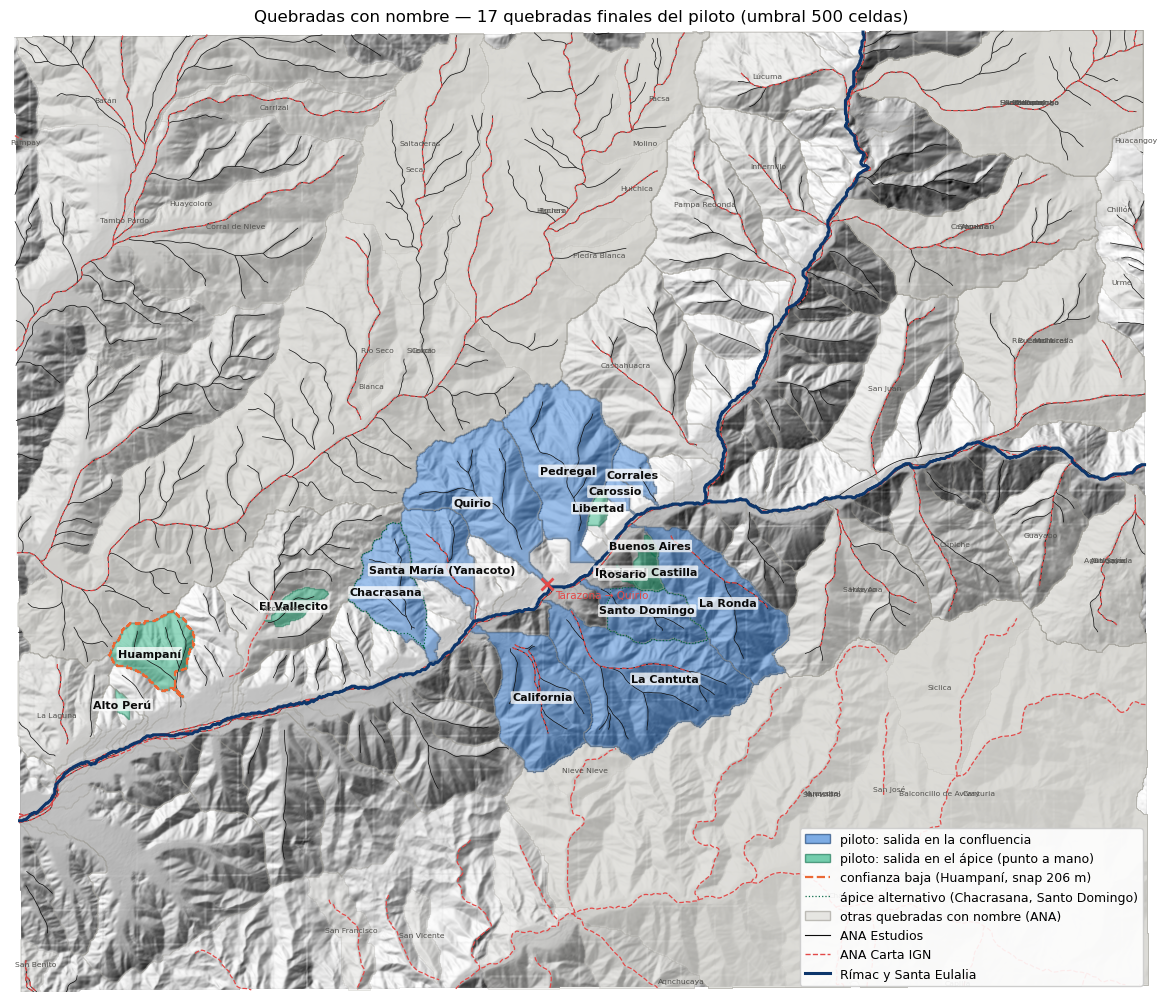

In [12]:
def geom_final(f):
    cid = f.cuenca_id
    if cid.isdigit(): return cand.loc[int(cid), "geometry"]
    if cid.startswith("R"): return g_ref.loc[cid, "geometry"]
    return pol_p[cid][1]
g_fin = gpd.GeoDataFrame(fin, geometry=[geom_final(f) for _, f in fin.iterrows()], crs=CRS)

fig, ax = plt.subplots(figsize=(15, 12.5))
ax.imshow(hs, cmap="gray", vmin=-0.2, vmax=1.0, extent=(X0, X1, Y0, Y1))
cand.boundary.plot(ax=ax, color="#9a9890", lw=0.3)
otros = cruce3[(cruce3.en_piloto != True) & cruce3.origen.isin(["candidata", "referencia"])]
g_otros = gpd.GeoDataFrame(otros, geometry=[cand.loc[int(c), "geometry"] if c.isdigit() else g_ref.loc[c, "geometry"] for c in otros.cuenca_id], crs=CRS)
g_otros.plot(ax=ax, color="#d9d8d3", alpha=0.35, edgecolor="#9a9890", lw=0.4)
for k, gl in ana.items():
    gl.clip(zona_valida).plot(ax=ax, color="#0b0b0b" if k == "ANA Estudios" else "#e34948", lw=0.5 if k == "ANA Estudios" else 0.9,
                              linestyle="-" if k == "ANA Estudios" else "--")
estilo = {"confluencia": ("#2a78d6", "#0d366b"), "apice": ("#1baf7a", "#0b6b49")}
for st, (fc, ec) in estilo.items():
    g_fin[g_fin.salida_tipo == st].plot(ax=ax, color=fc, alpha=0.45, edgecolor=ec, lw=1.0)
g_fin[g_fin.confianza_cuenca == "baja"].boundary.plot(ax=ax, color="#eb6834", lw=1.6, linestyle="--")
g_alt.boundary.plot(ax=ax, color="#0b6b49", lw=0.9, linestyle=":")
for v in xy_rio.values():
    ax.plot(v[:, 0], v[:, 1], color="#0d366b", lw=2.2)
for _, f in g_fin.iterrows():
    pt = f.geometry.representative_point()
    ax.text(pt.x, pt.y, f.nombre, fontsize=8, fontweight="bold", ha="center", va="center", color="#0b0b0b",
            bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.75))
for _, f in g_otros.iterrows():
    pt = f.geometry.representative_point()
    ax.text(pt.x, pt.y, f.nombre.replace("Quebrada ", ""), fontsize=5.5, ha="center", va="center", color="#52514e")
ax.plot(xt, yt, marker="x", color="#e34948", ms=8, mew=2); ax.annotate("Tarazona → Quirio", (xt, yt), xytext=(6, -10), textcoords="offset points", fontsize=7.5, color="#e34948")
ax.set_xlim(X0, X1); ax.set_ylim(Y0, Y1); ax.set_axis_off()
ax.legend(handles=[Patch(fc="#2a78d6", alpha=0.6, ec="#0d366b", label="piloto: salida en la confluencia"),
                   Patch(fc="#1baf7a", alpha=0.6, ec="#0b6b49", label="piloto: salida en el ápice (punto a mano)"),
                   Line2D([], [], color="#eb6834", lw=1.6, ls="--", label="confianza baja (Huampaní, snap 206 m)"),
                   Line2D([], [], color="#0b6b49", lw=0.9, ls=":", label="ápice alternativo (Chacrasana, Santo Domingo)"),
                   Patch(fc="#d9d8d3", alpha=0.6, ec="#9a9890", label="otras quebradas con nombre (ANA)"),
                   Line2D([], [], color="#0b0b0b", lw=0.8, label="ANA Estudios"), Line2D([], [], color="#e34948", lw=1, ls="--", label="ANA Carta IGN"),
                   Line2D([], [], color="#0d366b", lw=2.2, label="Rímac y Santa Eulalia")], loc="lower right", fontsize=9, framealpha=0.9)
ax.set_title(f"Quebradas con nombre — {len(fin)} quebradas finales del piloto (umbral {UMBRAL_CAUCE} celdas)", fontsize=12)
fig.savefig(TERRENO / "cuencas_con_nombres.png", dpi=160, bbox_inches="tight")
plt.show()

## Fase 5 — Tabla de terreno (tabla 1): `terreno/quebradas.csv`
Solo las quebradas finales del piloto (con cuenca y `en_piloto = True`; sin Huaycoloro ni Río Seco).
- **DEM:** pendiente y cotas salen del FABDEM **original** en UTM (`fabdem_chosica_utm18s.tif`), no del corregido con `breach_depressions` (esa corrección rebaja algunos cauces).
- **Pendiente:** `wbt.slope`, en grados. `pendiente_media` = promedio dentro de la cuenca.
- **Melton** = (cota máx − cota mín) / √(área en m²).
- **`largo_cauce_km`:** desde la salida, siguiendo la mayor acumulación hasta la divisoria.

In [13]:
DEM_UTM = RAIZ / "fabdem_chosica_utm18s.tif"
PEND_TIF = TERRENO / "pendiente_grados.tif"
assert wbt.slope(str(DEM_UTM), str(PEND_TIF), units="degrees") == 0
with rasterio.open(PEND_TIF) as src:
    pend_g = src.read(1); pend_g = np.where(pend_g == src.nodata, np.nan, pend_g)
with rasterio.open(DEM_UTM) as src:
    assert src.transform == T and src.shape == (R, C)
    dem0 = src.read(1).astype(float); dem0[dem0 == src.nodata] = np.nan

def largo_hasta_divisoria(r, c):
    # Cauce principal: hacia arriba por la mayor acumulación hasta la divisoria (sin umbral).
    i, largo = idx[r, c], 0.0
    while True:
        h = hijos(i)
        if len(h) == 0: return largo / 1000
        j = h[np.argmax(acc_r[h])]; largo += paso_r[j]; i = j

filas = []
for _, f in fin.iterrows():
    m = masc_fin[f.quebrada_id]; r0, c0 = rc_fin[f.quebrada_id]
    x, y = rasterio.transform.xy(T, r0, c0); lon, lat = warp_transform(CRS, "EPSG:4326", [x], [y])
    zmax, zmin = float(np.nanmax(dem0[m])), float(np.nanmin(dem0[m]))
    area_m2 = m.sum() * CELDA_M2
    filas.append({"quebrada_id": f.quebrada_id, "nombre": f.nombre, "alias": f.alias, "origen": f.origen, "cuenca_id": f.cuenca_id,
                  "salida_tipo": f.salida_tipo, "confianza_cuenca": f.confianza_cuenca,
                  "salida_lat": round(lat[0], 6), "salida_lon": round(lon[0], 6), "area_km2": round(area_m2 / 1e6, 3),
                  "cuenca_pequena": bool(area_m2 / 1e6 < 0.3), "pendiente_media": round(float(np.nanmean(pend_g[m])), 1),
                  "cota_max_m": round(zmax), "cota_min_m": round(zmin), "melton": round((zmax - zmin) / np.sqrt(area_m2), 3),
                  "largo_cauce_km": round(largo_hasta_divisoria(r0, c0), 2), "toca_borde": bool((m & borde).any())})
tab = pd.DataFrame(filas)
# Control con el Cuadro Nº 04 (área, largo, cotas)
CUADRO04_CTRL = {"santa_maria": (4.6, 5.0, 1650, 755), "quirio": (10.4, 5.6, 2010, 805), "pedregal": (10.6, 6.1, 2330, 820),
                 "carossio": (0.4, 1.3, 1675, 840), "corrales": (1.4, 2.4, 2000, 850), "la_cantuta": (15.0, 6.7, 2210, 800), "la_ronda": (9.0, 5.6, 2210, 890)}
ctrl = tab[tab.quebrada_id.isin(CUADRO04_CTRL)][["quebrada_id", "area_km2", "largo_cauce_km", "cota_max_m", "cota_min_m"]].copy()
for k, col in enumerate(["area_ref", "largo_ref", "zmax_ref", "zmin_ref"]):
    ctrl[col] = ctrl.quebrada_id.map(lambda q: CUADRO04_CTRL[q][k])
print("Control contra el Cuadro Nº 04:"); display(ctrl)

Control contra el Cuadro Nº 04:


,quebrada_id,area_km2,largo_cauce_km,cota_max_m,cota_min_m,area_ref,largo_ref,zmax_ref,zmin_ref
0,carossio,0.528,1.47,1679,877,0.4,1.3,1675,840
1,corrales,1.259,2.20,1927,895,1.4,2.4,2000,850
2,pedregal,9.982,6.47,2324,839,10.6,6.1,2330,820
4,la_cantuta,13.888,7.86,2203,797,15.0,6.7,2210,800
5,la_ronda,8.818,7.63,2311,870,9.0,5.6,2210,890
6,quirio,9.824,6.31,2026,804,10.4,5.6,2010,805
7,santa_maria,4.200,4.39,1856,753,4.6,5.0,1650,755


## Paso 10 — Susceptibilidad a movimientos en masa (INGEMMET), con las dos capas
- **Vectorial regional:** intersecto cada cuenca con los polígonos (corregidos con `make_valid`) y sumo el área por clase. La clase 0 ("sin clase") no entra al denominador.
- **Imagen nacional de 200 m:** la paso a la grilla de 30 m (vecino más cercano) y cuento las celdas de la cuenca, así que cada clase pesa según su área.
- **Indicadores:** % del área en clase ≥ 4, % en clase 5 y clase promedio ponderada por área. Clases: 1 Muy baja … 5 Muy alta.

In [14]:
from rasterio.warp import reproject, Resampling
gv = gpd.read_file(FUENTES / "ingemmet_susceptibilidad_mm.geojson")
gv["geometry"] = gv.make_valid()
gv = gv.to_crs(CRS)
gv = gv[gv.geom_type.isin(["Polygon", "MultiPolygon", "GeometryCollection"])]
gv = gv[gv.LEYENDA > 0]
idx_v = gv.sindex

with rasterio.open(FUENTES / "ingemmet_susceptibilidad_mm_200m.tif") as src:
    img30 = np.zeros((R, C), np.uint8)
    reproject(src.read(1), img30, src_transform=src.transform, src_crs=src.crs, dst_transform=T, dst_crs=CRS, resampling=Resampling.nearest)

def indicadores(areas):
    # areas: dict clase -> área (cualquier unidad)
    tot = sum(areas.values())
    if tot == 0: return np.nan, np.nan, np.nan, 0
    ge4 = sum(a for k, a in areas.items() if k >= 4); c5 = areas.get(5, 0)
    media = sum(k * a for k, a in areas.items()) / tot
    return round(100 * ge4 / tot, 1), round(100 * c5 / tot, 1), round(media, 2), tot

filas = []
for _, f in g_fin.iterrows():
    q = f.quebrada_id; poly = f.geometry; m = masc_fin[q]; area = m.sum() * CELDA_M2
    sub = gv.iloc[idx_v.query(poly, predicate="intersects")]
    inter = sub.geometry.intersection(poly)
    a_v = inter.area.groupby(sub.LEYENDA.values).sum().to_dict()
    v_ge4, v_5, v_media, v_tot = indicadores(a_v)
    vals = img30[m]; vals = vals[(vals >= 1) & (vals <= 5)]
    a_i = {int(k): int(n) * CELDA_M2 for k, n in zip(*np.unique(vals, return_counts=True))}
    i_ge4, i_5, i_media, i_tot = indicadores(a_i)
    filas.append({"quebrada_id": q, "vec_ge4_pct": v_ge4, "vec_c5_pct": v_5, "vec_media": v_media, "vec_cobertura_pct": round(100 * v_tot / area, 1),
                  "img_ge4_pct": i_ge4, "img_c5_pct": i_5, "img_media": i_media, "img_cobertura_pct": round(100 * i_tot / area, 1),
                  "img_pixeles_200m": round(area / 200 ** 2, 1)})
sus = pd.DataFrame(filas)
display(sus)
print("Correlación entre capas (por cuenca):",
      {k: round(sus[f"vec_{k}"].corr(sus[f"img_{k}"]), 2) for k in ["ge4_pct", "c5_pct", "media"]})
print("Variación entre cuencas (desv. estándar):", {c: round(sus[c].std(), 1) for c in ["vec_ge4_pct", "vec_c5_pct", "img_ge4_pct", "img_c5_pct"]})

,quebrada_id,vec_ge4_pct,vec_c5_pct,vec_media,vec_cobertura_pct,img_ge4_pct,img_c5_pct,img_media,img_cobertura_pct,img_pixeles_200m
0,carossio,96.6,3.3,4.00,100.0,28.8,0.0,3.29,100.0,13.2
1,corrales,91.5,0.0,3.91,100.0,15.1,0.0,3.15,100.0,31.5
2,pedregal,86.9,1.3,3.88,100.0,8.6,0.0,2.99,100.0,249.5
3,california,91.1,2.4,3.93,100.0,0.0,0.0,2.85,100.0,210.8
4,la_cantuta,91.5,0.6,3.92,100.0,5.0,0.0,2.93,100.0,347.2
5,la_ronda,93.0,0.8,3.94,100.0,8.6,0.0,3.00,100.0,220.5
6,quirio,88.0,0.6,3.89,100.0,42.4,20.0,3.55,100.0,245.6
7,santa_maria,93.5,1.9,3.95,100.0,46.0,26.0,3.68,100.0,105.0
8,chacrasana,89.0,3.3,3.92,100.0,12.7,0.0,3.05,100.0,124.8
9,libertad,95.6,0.0,3.96,100.0,0.0,0.0,2.98,100.0,10.2


Correlación entre capas (por cuenca): {'ge4_pct': np.float64(0.13), 'c5_pct': np.float64(-0.05), 'media': np.float64(0.3)}
Variación entre cuencas (desv. estándar): {'vec_ge4_pct': 4.3, 'vec_c5_pct': 3.5, 'img_ge4_pct': 18.6, 'img_c5_pct': 7.7}


In [15]:
quebradas = tab.merge(sus, on="quebrada_id")
cols_q = ["quebrada_id", "nombre", "alias", "origen", "cuenca_id", "salida_tipo", "confianza_cuenca", "salida_lat", "salida_lon",
          "area_km2", "cuenca_pequena", "pendiente_media", "cota_max_m", "cota_min_m", "melton", "largo_cauce_km", "toca_borde",
          "vec_ge4_pct", "vec_c5_pct", "vec_media", "vec_cobertura_pct", "img_ge4_pct", "img_c5_pct", "img_media", "img_cobertura_pct"]
quebradas[cols_q].to_csv(TERRENO / "quebradas.csv", index=False, encoding="utf-8-sig")
g_out = g_fin[["quebrada_id", "geometry"]].merge(quebradas[cols_q], on="quebrada_id")
g_out.to_crs("EPSG:4326").to_file(TERRENO / "quebradas.geojson", driver="GeoJSON")
g_out.to_crs("EPSG:4326").assign(Name=lambda d: d.nombre).astype({"cuenca_pequena": str, "toca_borde": str}).to_file(TERRENO / "quebradas.kml", driver="KML")
print(f"quebradas.csv: {len(quebradas)} quebradas")
display(quebradas[["quebrada_id", "origen", "salida_tipo", "confianza_cuenca", "area_km2", "pendiente_media", "cota_max_m", "cota_min_m", "melton", "largo_cauce_km"]])

quebradas.csv: 17 quebradas


,quebrada_id,origen,salida_tipo,confianza_cuenca,area_km2,pendiente_media,cota_max_m,cota_min_m,melton,largo_cauce_km
0,carossio,candidata,confluencia,alta,0.528,35.6,1679,877,1.103,1.47
1,corrales,candidata,confluencia,alta,1.259,34.4,1927,895,0.920,2.20
2,pedregal,candidata,confluencia,alta,9.982,29.0,2324,839,0.470,6.47
3,california,candidata,confluencia,alta,8.430,27.0,1699,742,0.330,6.01
4,la_cantuta,candidata,confluencia,alta,13.888,30.1,2203,797,0.377,7.86
5,la_ronda,candidata,confluencia,alta,8.818,31.8,2311,870,0.485,7.63
6,quirio,candidata,confluencia,alta,9.824,29.5,2026,804,0.390,6.31
7,santa_maria,candidata,confluencia,alta,4.200,28.8,1856,753,0.538,4.39
8,chacrasana,ubicada,confluencia,alta,4.991,28.5,1804,713,0.488,4.82
9,libertad,ubicada,apice,alta,0.408,32.9,1527,956,0.894,1.00


## Cierre del camino del terreno: elección de variables para la versión 1
- **Correlaciones:** Pearson (relación lineal) y Spearman (por rangos, más robusta con 17 quebradas) entre log10(área), pendiente media, Melton, largo del cauce e `img_media`.
- **Ápice vs confluencia:** ¿`salida_tipo` está asociada con Melton? Las cuencas de ápice dejan fuera el cono, así que su cota mínima es más alta.
- **Criterio para las 2 variables:** una de tamaño y una de pendiente, con |r| ≤ 0.7 en Pearson y en Spearman. **No se usan los eventos del catálogo.**

In [16]:
q = pd.read_csv(TERRENO / "quebradas.csv")
X = pd.DataFrame({"log10_area": np.log10(q.area_km2), "pendiente_media": q.pendiente_media, "melton": q.melton,
                  "largo_cauce_km": q.largo_cauce_km, "img_media": q.img_media})
pearson, spearman = X.corr("pearson").round(2), X.corr("spearman").round(2)
print("Pearson:"); display(pearson)
print("Spearman:"); display(spearman)

g = q.groupby("salida_tipo")["melton"]
print("Melton por salida_tipo:"); display(g.agg(["count", "median", "min", "max"]).round(3))
from scipy.stats import mannwhitneyu
u = mannwhitneyu(q.loc[q.salida_tipo == "apice", "melton"], q.loc[q.salida_tipo == "confluencia", "melton"])
print(f"Mann-Whitney (ápice vs confluencia): p = {u.pvalue:.3f}")
print("Área y pendiente media por salida_tipo:"); display(q.groupby("salida_tipo")[["area_km2", "pendiente_media"]].agg(["median", "min", "max"]).round(2))
u2 = mannwhitneyu(q.loc[q.salida_tipo == "apice", "pendiente_media"], q.loc[q.salida_tipo == "confluencia", "pendiente_media"])
print(f"Mann-Whitney pendiente_media (ápice vs confluencia): p = {u2.pvalue:.3f}")

Pearson:


,log10_area,pendiente_media,melton,largo_cauce_km,img_media
log10_area,1.00,-0.69,-0.92,0.95,-0.18
pendiente_media,-0.69,1.00,0.81,-0.64,0.25
melton,-0.92,0.81,1.00,-0.82,0.27
largo_cauce_km,0.95,-0.64,-0.82,1.00,-0.18
img_media,-0.18,0.25,0.27,-0.18,1.00


Spearman:


,log10_area,pendiente_media,melton,largo_cauce_km,img_media
log10_area,1.00,-0.62,-0.91,0.98,-0.19
pendiente_media,-0.62,1.00,0.75,-0.60,0.29
melton,-0.91,0.75,1.00,-0.88,0.37
largo_cauce_km,0.98,-0.60,-0.88,1.00,-0.21
img_media,-0.19,0.29,0.37,-0.21,1.00


Melton por salida_tipo:


,count,median,min,max
salida_tipo,,,,
apice,7,0.894,0.471,1.659
confluencia,10,0.486,0.330,1.103


Mann-Whitney (ápice vs confluencia): p = 0.043
Área y pendiente media por salida_tipo:


area_km2              pendiente_media            
              median   min    max          median   min   max
salida_tipo                                                  
apice           0.41  0.14   3.48            32.9  28.8  35.6
confluencia     6.71  0.53  13.89            29.8  27.0  35.6

Mann-Whitney pendiente_media (ápice vs confluencia): p = 0.204


In [17]:
TAMANO, PENDIENTE = ["log10_area", "largo_cauce_km"], ["pendiente_media", "melton"]
pares = []
for a in TAMANO:
    for b in PENDIENTE:
        rp, rs = pearson.loc[a, b], spearman.loc[a, b]
        pares.append({"tamaño": a, "pendiente": b, "pearson": rp, "spearman": rs, "max_abs_r": max(abs(rp), abs(rs)),
                      "cumple_0.7": max(abs(rp), abs(rs)) <= 0.7})
pares = pd.DataFrame(pares).sort_values("max_abs_r")
display(pares)

,tamaño,pendiente,pearson,spearman,max_abs_r,cumple_0.7
2,largo_cauce_km,pendiente_media,-0.64,-0.60,0.64,True
0,log10_area,pendiente_media,-0.69,-0.62,0.69,True
3,largo_cauce_km,melton,-0.82,-0.88,0.88,False
1,log10_area,melton,-0.92,-0.91,0.92,False


**Decisión para la versión 1:** `log10(area_km2)` (tamaño) + `pendiente_media` (pendiente).
- Es el par más estándar que cumple |r| ≤ 0.7 (Pearson −0.69, Spearman −0.62). Largo + pendiente también cumple (−0.64), pero el largo D8 zigzaguea y es casi lo mismo que el área (r = 0.95).
- Melton queda fuera: está muy correlacionado con el área (−0.92) y es más alto en las cuencas de ápice por cómo se delimitaron, un artefacto. La pendiente media no depende del tipo de salida (Mann-Whitney p = 0.20).
- Susceptibilidad INGEMMET fuera de la v1; las columnas `vec_*` e `img_*` quedan para un experimento posterior.
- Las etiquetas por `quebrada_id` se generan con `catalogo_huaicos_chosica/etiquetas_por_quebrada.py`.